> **Historical two-second baseline (22 October).** This notebook keeps its explicit two-second settings for reference. The current default is three seconds; see `03_preprocessing_experiments.ipynb` and `python -m src.train`. Outputs from this notebook are written under `data/processed/baseline_2s/`.

# Preprocessing and chroma exploration

This notebook inventories the local dataset and compares **training** recordings of A, Am, C and E. It does not train a classifier or select settings using the test set. The original `01_exploration.ipynb` is preserved.

Run all cells from the repository root or `notebooks/` using the project Python environment. Outputs are written to `data/processed/`. File paths in metadata are relative to `data/raw/data/`.

### Set up paths and settings

Import the tools and find the project folder. The constants below keep this historical experiment at two seconds. Printing package versions makes the run easier to reproduce.

In [2]:
from pathlib import Path
import sys
import importlib.metadata
import json
import numpy as np
import pandas as pd
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/features.py").is_file():
    raise RuntimeError("Run from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.dataset import inspect_dataset
from src.features import preprocess_audio, chromagram, PITCH_CLASSES

DATA = ROOT / "data/raw/data"
OUTPUT = ROOT / "data/processed/baseline_2s"
OUTPUT.mkdir(parents=True, exist_ok=True)
SR, DURATION, TOP_DB, HOP = 22050, 2.0, 30.0, 512
versions = {name: importlib.metadata.version(name) for name in
            ("librosa", "numpy", "pandas", "matplotlib", "soundfile")}
print(versions)

{'librosa': '1.0.0', 'numpy': '2.5.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'soundfile': '0.14.0'}


## Dataset inventory

Header inspection covers both provided partitions; feature and preprocessing exploration below uses only Train. `Noise` remains in the inventory but has no chord label. Instrument/player identifiers are unknown: the dataset card describes a single guitar/player, but provides no reliable per-file IDs. No audio files are renamed or changed.

original_split,Test,Train
source_label,,
A,6,25
A#,6,25
A#m,6,25
Am,6,40
B,6,25
Bm,6,25
C,6,25
C#,6,25
C#m,6,25


count       mean        std        min        25%  \
original_split is_chord                                                      
Test           False       3.0  50.903932  10.261688  40.309546  45.957429   
               True      144.0   5.703726   0.263257   5.008617   5.522449   
Train          False       3.0  43.733333   6.466323  40.000000  40.000000   
               True      630.0   5.625006   0.285411   3.851247   5.452608   

                               50%        75%        max  
original_split is_chord                                   
Test           False     51.605312  56.201125  60.796937  
               True       5.667120   5.866667   6.644898  
Train          False     40.000000  45.600000  51.200000  
               True       5.567347   5.766893   7.622676

files
sample_rate channels format subtype       
16000       1        WAV    PCM_16       2
44100       1        WAV    PCM_16     745
            2        WAV    PCM_16      32
48000       2        WAV    PCM_24       1

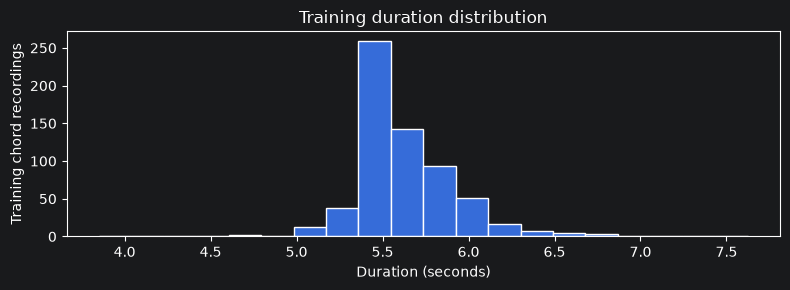

In [3]:
metadata = inspect_dataset(DATA)
metadata.to_csv(OUTPUT / "audio_inventory.csv", index=False)
display(pd.crosstab(metadata.source_label, metadata.original_split))
display(metadata.groupby(["original_split", "is_chord"]).duration_s.describe())
display(metadata.groupby(["sample_rate", "channels", "format", "subtype"]).size().rename("files").to_frame())
train = metadata[(metadata.original_split == "Train") & metadata.is_chord].copy()
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(train.duration_s, bins=20, edgecolor="white")
ax.set(xlabel="Duration (seconds)", ylabel="Training chord recordings", title="Training duration distribution")
plt.tight_layout()
plt.show()

## Inspect activity detection before trusting a crop

`librosa.effects.trim` finds frames with RMS energy within `top_db` decibels of the loudest frame. Larger `top_db` values keep quieter audio, including potentially more background noise. We start at 30 dB and retain the first two seconds after the detected boundary. Boundaries have frame-level precision and may include a little leading quiet.

This is **not semantic chord-onset detection**: a loud handling sound may trigger it early. Onset detection based on spectral changes is another candidate, but slow strums and repeated strums can produce ambiguous onsets. Inspect the shaded crops and listen before making a later training/validation comparison. A fixed two-second window can miss part of a slow strum or repeated-strumming sequence. These settings are starting assumptions, not validated optimal choices.

A, Am, C and E are selected deliberately to compare different pitch sets, including the major/minor difference. For each, use the first sorted Fender-named training file ending in `_1.wav` (fall back to first sorted training path).

,chord,filepath,duration_s
0,A,Train/A/A_acoustic_guitar_fender_fa_series_1.wav,5.607256
75,Am,Train/Am/Am_acoustic_guitar_fender_fa_series_1...,5.307937
165,C,Train/C/C_acoustic_guitar_fender_fa_series_1.wav,5.647166
365,E,Train/E/E_acoustic_guitar_fender_fa_series_1.wav,5.407710


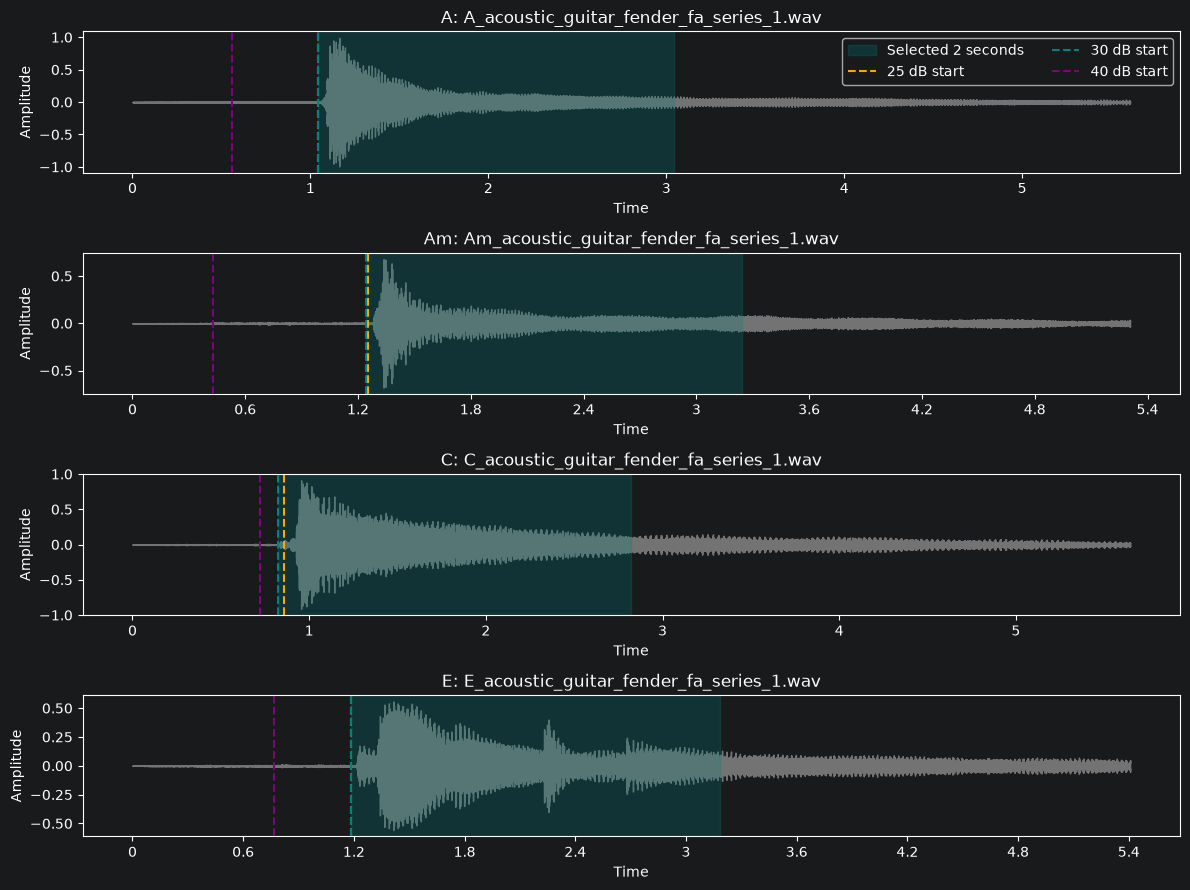

top_db,25,30,40
chord,,,
A,1.044898,1.044898,0.557279
Am,1.253878,1.242268,0.429569
C,0.859138,0.824308,0.719819
E,1.184218,1.184218,0.766259


In [4]:
examples = []
for chord in ("A", "Am", "C", "E"):
    candidates = train[train.chord == chord].sort_values("filepath")
    first_take = candidates[candidates.filepath.str.contains("fender", case=False) & candidates.filepath.str.endswith("_1.wav")]
    examples.append((first_take if not first_take.empty else candidates).iloc[0])
examples = pd.DataFrame(examples)
display(examples[["chord", "filepath", "duration_s"]])

fig, axes = plt.subplots(len(examples), 1, figsize=(12, 9), squeeze=False)
threshold_rows = []
prepared = {}
for ax, row in zip(axes[:, 0], examples.itertuples()):
    path = DATA / row.filepath
    raw, _ = librosa.load(path, sr=SR, mono=True)
    audio, sr, info = preprocess_audio(path, sr=SR, duration=DURATION, top_db=TOP_DB, min_duration=DURATION)
    prepared[row.chord] = (audio, chromagram(audio, sr, hop_length=HOP), info)
    librosa.display.waveshow(raw, sr=sr, ax=ax, color="0.45")
    ax.axvspan(info["start_s"], info["stop_s"], alpha=0.25, color="teal", label="Selected 2 seconds")
    for threshold, color in ((25, "orange"), (30, "teal"), (40, "purple")):
        _, bounds = librosa.effects.trim(raw, top_db=threshold, frame_length=2048, hop_length=256)
        start = bounds[0] / sr
        threshold_rows.append({"chord": row.chord, "top_db": threshold, "start_s": start})
        ax.axvline(start, color=color, linestyle="--", label=f"{threshold} dB start")
    ax.set(title=f"{row.chord}: {Path(row.filepath).name}", ylabel="Amplitude")
axes[0, 0].legend(loc="upper right", ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "preprocessing_comparison.png", dpi=150)
plt.show()
display(pd.DataFrame(threshold_rows).pivot(index="chord", columns="top_db", values="start_s"))

### Listen to the selected audio

Play each original file, then its crop. The crop player has automatic volume adjustment turned off, so quiet sections stay quiet.

In [5]:
# Optional playback: original and selected crop. Automatic normalisation is off.
for row in examples.itertuples():
    print(row.chord, "— original, then selected crop")
    display(Audio(filename=str(DATA / row.filepath)))
    display(Audio(prepared[row.chord][0], rate=SR, normalize=False))

A — original, then selected crop


Am — original, then selected crop


C — original, then selected crop


E — original, then selected crop


## Chromagrams and fixed-length features

CQT-based chroma folds frequencies into 12 pitch classes, discarding octave information. Each time frame is normalized to its largest pitch-class value; averaging over time gives **12 features** in C, C#, D, D#, E, F, F#, G, G#, A, A#, B order. No scaling statistics are fitted across recordings.

Expected chord tones are A–C#–E for A, A–C–E for Am, C–E–G for C, and E–G#–B for E. Orange bars mark these expected tones, not labels inferred from the audio. Harmonics, open strings, noise and strum timing can also energize other bins. Mean chroma loses temporal order and cannot distinguish voicings separated only by octaves. Six octaves from C2 cover standard guitar fundamentals and upper harmonics while avoiding very low-frequency filters that need longer audio. Fixed tuning is set to zero semitones relative to equal temperament; detuning is a future experiment.

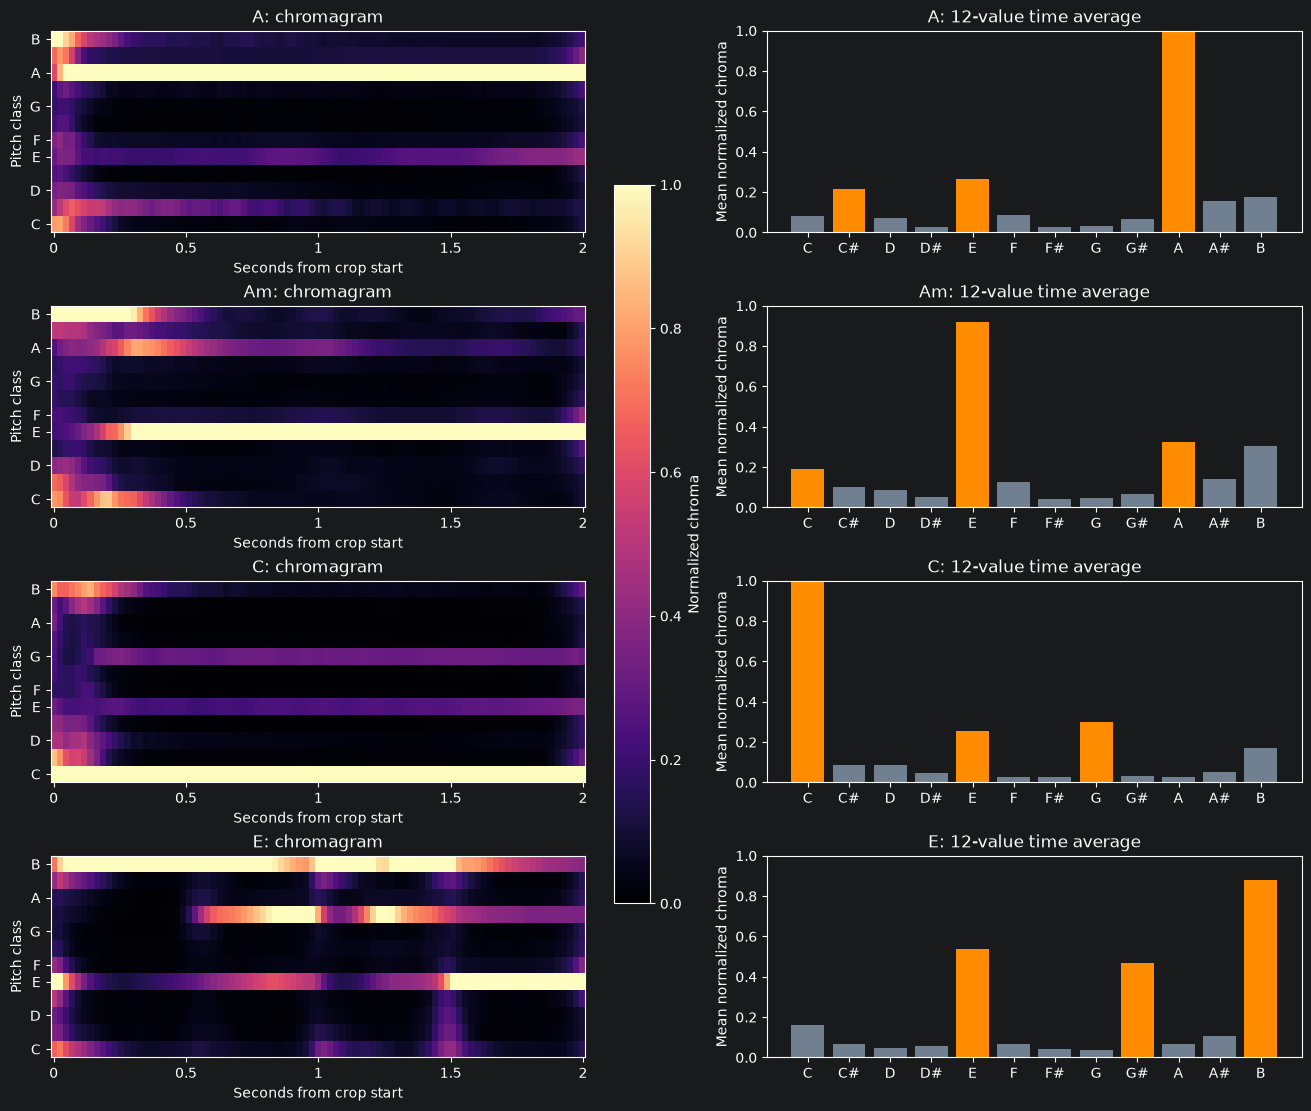

,C,C#,D,D#,E,F,F#,G,G#,A,A#,B
A,0.083675,0.213414,0.071101,0.029568,0.263736,0.087560,0.028096,0.031546,0.064457,0.993531,0.155305,0.177793
Am,0.192568,0.100023,0.084262,0.054171,0.920570,0.124718,0.041963,0.045343,0.064494,0.326766,0.141955,0.302950
C,1.000000,0.086230,0.085210,0.048017,0.254470,0.029015,0.027847,0.301347,0.032331,0.027069,0.054472,0.173066
E,0.163297,0.066835,0.049528,0.055528,0.537837,0.064526,0.042963,0.037148,0.470527,0.065661,0.105645,0.880989


In [6]:
expected = {"A": {"A", "C#", "E"}, "Am": {"A", "C", "E"},
            "C": {"C", "E", "G"}, "E": {"E", "G#", "B"}}
fig, axes = plt.subplots(len(prepared), 2, figsize=(13, 11), constrained_layout=True)
for (chord, (audio, chroma, info)), (left, right) in zip(prepared.items(), axes):
    img = librosa.display.specshow(chroma, sr=SR, hop_length=HOP, x_axis="time",
                                  y_axis="chroma", ax=left, vmin=0, vmax=1, cmap="magma")
    left.set(title=f"{chord}: chromagram", xlabel="Seconds from crop start")
    vector = chroma.mean(axis=1)
    colors = ["darkorange" if pitch in expected[chord] else "slategray" for pitch in PITCH_CLASSES]
    right.bar(PITCH_CLASSES, vector, color=colors)
    right.set(title=f"{chord}: 12-value time average", ylim=(0, 1), ylabel="Mean normalized chroma")
fig.colorbar(img, ax=axes[:, 0], label="Normalized chroma", shrink=0.7)
fig.savefig(OUTPUT / "chroma_comparison.png", dpi=150)
plt.show()
display(pd.DataFrame({chord: values[1].mean(axis=1) for chord, values in prepared.items()}, index=PITCH_CLASSES).T)

## Training feature matrix and quality checks

Apply the same settings independently to all training chord files. Report failures explicitly; do not silently substitute zero vectors. The test audio is not transformed here. When models are added, first split these training rows reproducibly into training/validation subsets and fit any scalers on training rows only. Use validation for choices of trimming, window length, features and classifier; evaluate the chosen pipeline on Test only afterward.

The matrix includes metadata for traceability, but only the 12 `chroma_` columns are model inputs. Never use filename, source label, or split as numeric predictors.

In [7]:
feature_rows, failures = [], []
for row in train.itertuples():
    try:
        audio, sr, info = preprocess_audio(DATA / row.filepath, sr=SR, duration=DURATION, top_db=TOP_DB, min_duration=DURATION)
        vector = chromagram(audio, sr, hop_length=HOP).mean(axis=1)
        if vector.shape != (12,) or not np.isfinite(vector).all():
            raise ValueError("Invalid feature vector")
        feature_rows.append({"filepath": row.filepath, "chord": row.chord,
                             "source_dataset": row.source_dataset,
                             "guitar_id": row.guitar_id, "player_id": row.player_id,
                             "original_split": row.original_split, **info,
                             **dict(zip([f"chroma_{p}" for p in PITCH_CLASSES], vector))})
    except (ValueError, RuntimeError, OSError) as exc:
        failures.append({"filepath": row.filepath, "error": str(exc)})
features = pd.DataFrame(feature_rows)
errors = pd.DataFrame(failures, columns=["filepath", "error"])
features.to_csv(OUTPUT / "train_chroma.csv", index=False)
errors.to_csv(OUTPUT / "feature_errors.csv", index=False)
(OUTPUT / "feature_config.json").write_text(json.dumps({
    "sample_rate": SR, "duration_s": DURATION, "top_db": TOP_DB,
    "trim_frame_length": 2048, "trim_hop_length": 256,
    "chroma_hop_length": HOP, "fmin_note": "C2", "n_octaves": 6, "tuning": 0.0, "normalization": "per-frame maximum",
    "pitch_classes": list(PITCH_CLASSES), "versions": versions,
}, indent=2))
print(f"Extracted {len(features)} / {len(train)} training recordings; failures: {len(errors)}")
display(errors)
feature_columns = [f"chroma_{p}" for p in PITCH_CLASSES]
X = features[feature_columns].to_numpy()
y = features.chord.to_numpy()
print("X:", X.shape, "y:", y.shape)
assert len(features) + len(errors) == len(train)
assert np.isfinite(X).all()
assert features.original_split.eq("Train").all()
display(features.groupby("chord").size().rename("successful_recordings").to_frame())
display(features[["start_s", "stop_s"]].describe())

Extracted 629 / 630 training recordings; failures: 1


,filepath,error
0,Train/E/E_classic_clean_garage_band_3.wav,Less than 2s after trimming: C:\Users\Marcus\D...


X: (629, 12) y: (629,)


,successful_recordings
chord,
A,25
A#,25
A#m,25
Am,40
B,25
Bm,25
C,25
C#,25
C#m,25


,start_s,stop_s
count,629.000000,629.000000
mean,0.688163,2.688163
std,0.261776,0.261776
min,0.000000,2.000000
25%,0.545669,2.545669
50%,0.673379,2.673379
75%,0.835918,2.835918
max,1.776327,3.776327


## What this establishes (and what remains)

The figures let us check whether expected pitch classes appear and whether activity-based cropping avoids the initial silence. This is a feature sanity check, not a classification result. Four examples cannot establish robustness for all playing techniques. Review unusually early/late boundaries and extraction failures before training.

The dataset has unequal training class counts and limited instrument coverage. Accuracy on its provided test partition will not establish unseen-guitar generalisation. Next: a reproducible training/validation split and a simple Random Forest baseline, followed by validation-based comparisons.

Dataset source: [severyn-k/isolated-guitar-chords](https://huggingface.co/datasets/severyn-k/isolated-guitar-chords), CC BY 4.0. The inventory reflects the downloaded files, which may differ from the dataset card's approximate counts.

## Observations from this local run

- The inventory contains 630 training chord files, 144 test chord files and six noise files. Am/E have extra GarageBand-named files; their provenance needs investigation before any cross-instrument claims.
- The 40 dB activity threshold starts early on background sound in some comparison recordings. The 30 dB crops are a plausible baseline, with settings still to be compared on validation data.
- Extraction succeeds for 629/630 training files. `Train/E/E_classic_clean_garage_band_3.wav` has less than two seconds after trimming. It is explicitly reported, and should be reviewed before training.
- These figures are visual sanity checks. They do not measure classification performance or prove that every selected crop is correct.